In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import bags_array
import approximation as app 
import re

from scipy.optimize import minimize

In [2]:
folder = r"C:\Users\misha\Desktop\data\data\clear_water\F33\F33_20000"
bags_array = bags_array.bags_array(folder)
df = bags_array[0]

[np.str_('F33_20000_1.dat'), np.str_('F33_20000_10.dat'), np.str_('F33_20000_11.dat'), np.str_('F33_20000_12.dat'), np.str_('F33_20000_13.dat'), np.str_('F33_20000_14.dat'), np.str_('F33_20000_15.dat'), np.str_('F33_20000_16.dat'), np.str_('F33_20000_17.dat'), np.str_('F33_20000_18.dat'), np.str_('F33_20000_19.dat'), np.str_('F33_20000_21.dat'), np.str_('F33_20000_27.dat'), np.str_('F33_20000_3.dat'), np.str_('F33_20000_3.dat.backup30.07.2026 20-18-44'), np.str_('F33_20000_3.dat.backup30.07.2026 20-56-54'), np.str_('F33_20000_4.dat'), np.str_('F33_20000_6.dat'), np.str_('F33_20000_8.dat')]


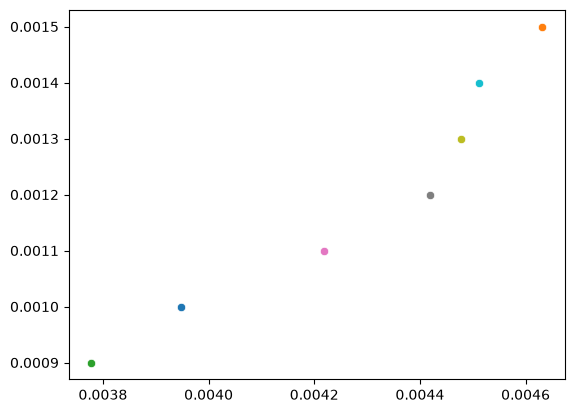

In [3]:
Time = []
canopy_R = []
canopy_x0 = []
canopy_y0 = []

for name, group in df.groupby(by='frame_start', sort=False):
    if len(group) < 3:
        continue
    subgroup = group[group['name'] == '']
    x0_start, y0_start, R_start = None , None , None
    x0_start, y0_start, R_start = app.appr_circle(subgroup['x_start'], subgroup['y_start'])
    Time.append(name)
    canopy_R.append(float(R_start))
    canopy_x0.append(float(x0_start))
    canopy_y0.append(float(y0_start))
    sns.scatterplot(x=[R_start], y=[name])
plt.show()

Time = np.array(Time)
canopy_R = np.array(canopy_R)
canopy_x0 = np.array(canopy_x0)
canopy_y0 = np.array(canopy_y0)

mask = np.isnan(canopy_R)
Time = Time[~mask]
canopy_R = canopy_R[~mask]
canopy_x0 = canopy_x0[~mask]
canopy_y0 = canopy_y0[~mask]


Time, canopy_x0, canopy_y0, canopy_R = zip(*sorted(zip(Time, canopy_x0, canopy_y0, canopy_R)))

In [4]:
Time_coeff = []
A = []
B = []
C = []
center_x = []
center_y = []
center_z = []
Rho = []

for name, group in df.groupby(by='frame_start', sort=False):
    if len(group) < 3:
        continue
    subgroup = group[group['name'].str.contains(r'r\d+')]
    canopy_interp_R = np.interp(name, Time, canopy_R)
    canopy_interp_x0 = np.interp(name, Time, canopy_x0)
    canopy_interp_y0 = np.interp(name, Time, canopy_y0)

    x = subgroup['x_start'] - canopy_interp_x0
    y = subgroup['y_start']- canopy_interp_y0
    z = canopy_interp_R**2 - x**2 - y**2

    if len(x) > 3:
        a, b, c = app.appr_f(x, y, z)
        center, rho, e1, e2 = app.appr_circle_in_plane(x, y, z, a, b, c)
        A.append(a)
        B.append(b)
        C.append(c)

        center_point_x, center_point_y, center_point_z = center
        center_x.append(center_point_x)
        center_y.append(center_point_y)
        center_z.append(center_point_z)
        
        Rho.append(rho)
        Time_coeff.append(name)

Time_coeff = np.array(Time_coeff)
A = np.array(A)
B = np.array(B)
C = np.array(C)

center_x = np.array(center_x)
center_y = np.array(center_y)
center_z = np.array(center_z)

Rho = np.array(Rho)

Количество точек: 101
min/max: 0.09031883434344527 5.560489350382451


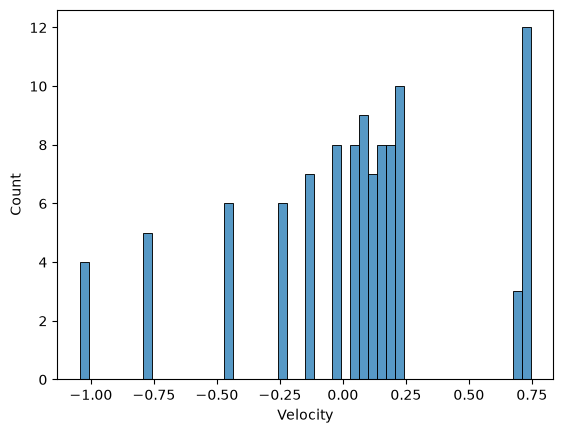

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Velocity = []
Time_velocity = []
Teta_velocity = []
R_velocity = []

for name, group in df.groupby(by='name', sort=False):
    subgroup = group[group['name'].str.contains(r'\d+')]
    if subgroup.empty:
        continue

    # --- переводим столбцы в numpy-массивы ---
    frame_start = subgroup['frame_start'].to_numpy(dtype=float)
    frame_end   = subgroup['frame_end'].to_numpy(dtype=float)

    # --- интерполяция положения центра (в системе координат канопы) ---
    x_start = subgroup['x_start'].to_numpy(dtype=float) - np.interp(frame_start, Time, canopy_x0)
    y_start = subgroup['y_start'].to_numpy(dtype=float) - np.interp(frame_start, Time, canopy_y0)
    x_end   = subgroup['x_end'].to_numpy(dtype=float)   - np.interp(frame_end,   Time, canopy_x0)
    y_end   = subgroup['y_end'].to_numpy(dtype=float)   - np.interp(frame_end,   Time, canopy_y0)

    # --- интерполяция коэффициентов A, B, C ---
    A_start = np.interp(frame_start, Time_coeff, A)
    A_end   = np.interp(frame_end,   Time_coeff, A)
    B_start = np.interp(frame_start, Time_coeff, B)
    B_end   = np.interp(frame_end,   Time_coeff, B)
    C_start = np.interp(frame_start, Time_coeff, C)
    C_end   = np.interp(frame_end,   Time_coeff, C)

    # --- интерполяция центра ---
    center_x_start = np.interp(frame_start, Time_coeff, center_x)
    center_y_start = np.interp(frame_start, Time_coeff, center_y)

    # --- интерполяция Rho (ВАЖНО: и start, и end) ---
    Rho_start = np.interp(frame_start, Time_coeff, Rho)
    Rho_end   = np.interp(frame_end,   Time_coeff, Rho)

    # --- интерполяция радиуса канопы ---
    R_start = np.interp(frame_start, Time, canopy_R)
    R_end   = np.interp(frame_end,   Time, canopy_R)

    # --- защита от деления на ноль в arccos ---
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio_start = np.clip(Rho_start / R_start, -1.0, 1.0)
        ratio_end   = np.clip(Rho_end   / R_end,   -1.0, 1.0)

    teta_start = np.arccos(ratio_start)
    teta_end   = np.arccos(ratio_end)

    R_mean    = (R_start + R_end) / 2.0
    teta_mean = (teta_start + teta_end) / 2.0

    dR   = R_end   - R_start
    dt   = frame_end - frame_start
    dTeta = teta_end - teta_start

    # --- защита от dt == 0 ---
    with np.errstate(divide='ignore', invalid='ignore'):
        velocity = np.sqrt((R_mean * (dTeta / dt))**2 + (dR / dt)**2)

    velocity  = np.where(dt == 0, np.nan, velocity)
    time_mean = (frame_end + frame_start) / 2.0

    # --- extend + ravel, чтобы добавить именно числа, а не Series ---
    Velocity.extend(np.ravel(velocity))
    Time_velocity.extend(np.ravel(time_mean))
    Teta_velocity.extend(np.ravel(teta_mean))
    R_velocity.extend(np.ravel(R_mean))

# --- приводим к массивам и выкидываем NaN / inf ---
Velocity = np.asarray(Velocity, dtype=float)
Velocity = Velocity[np.isfinite(Velocity)]

print("Количество точек:", Velocity.size)
if Velocity.size:
    print("min/max:", Velocity.min(), Velocity.max())
else:
    print("Внимание: Velocity пуста — проверьте входные данные")

# --- график ---
sns.histplot(np.log10(Velocity), bins=50)
plt.xlabel("Velocity")
plt.ylabel("Count")
plt.show()

In [ ]:
time = 0; 

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label='parametric curve')